# TabR — Subject-Independent Behavioral Optical-Flow Features

Workflow TabR dengan split **berdasarkan subject_id**, bukan pertanyaan. Setiap subjek hanya berada di satu split.

- Train: 60% subjects
- Validation: 20% subjects
- Test: 20% subjects
- Stratified by subject label, fixed random seed
- Hyperparameter, best seed, event aggregation, dan threshold dipilih hanya dari Validation
- Test tetap tertutup sampai semua keputusan terkunci
- `RUN_TRAINING` otomatis aktif jika artefak belum ada, lalu Run All berikutnya otomatis melewati training


## 1. Setup
Memuat library proyek, mendefinisikan lokasi artefak baru, dan memakai konfigurasi tuning resmi TabR yang sudah digunakan eksperimen sebelumnya.

In [1]:
from __future__ import annotations

import copy
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import HTML, Markdown, display
from scipy.special import expit
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, log_loss, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'opticalflow' else Path.cwd().resolve()
if not (ROOT / 'third_party' / 'tabular-dl-tabr-official').exists():
    raise RuntimeError(f'Run notebook from project root or opticalflow/: {ROOT}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

TABR_ROOT = ROOT / 'third_party' / 'tabular-dl-tabr-official'
os.environ['PROJECT_DIR'] = str(TABR_ROOT)
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
if str(TABR_ROOT) not in sys.path:
    sys.path.append(str(TABR_ROOT))

import lib
import bin.go

CSV_PATH = ROOT / 'opticalflow' / 'dataset' / 'behavioral_features_events_long_unpadded.csv'
BASE_TUNING_TOML = TABR_ROOT / 'exp' / 'tabr' / 'convat_apex_anxiety' / '0-tuning.toml'
DATASET_NAME = 'convat_opticalflow_behavioral_subject_independent'
EXP_NAME = DATASET_NAME
DATA_DIR = TABR_ROOT / 'data' / DATASET_NAME
EXP_DIR = TABR_ROOT / 'exp' / 'tabr' / EXP_NAME
TUNING_TOML = EXP_DIR / '0-tuning.toml'
EVAL_DIR = EXP_DIR / '0-evaluation'
ENSEMBLE_DIR = EXP_DIR / '0-ensemble-5'
ARTIFACT_DIR = ROOT / 'opticalflow' / 'results' / EXP_NAME

TRAINING_CHECKPOINT = EXP_DIR / '0-tuning' / 'checkpoint.pt'
RUN_TRAINING = not TRAINING_CHECKPOINT.exists()  # first run trains; later Run All skips
SPLIT_SEED = 42
N_TUNING_TRIALS = 15
N_EVAL_SEEDS = 15
N_ENSEMBLES = 3
ENSEMBLE_SIZE = 5
SPLIT_LABELS = {'train': 'Train subjects (60%)', 'val': 'Validation subjects (20%)', 'test': 'Test subjects (20%)'}
LABEL_NAMES = ['anxiety_rendah', 'anxiety_tinggi']

display(pd.DataFrame({
    'Item': ['CSV', 'Dataset TabR', 'Experiment TabR', 'Run training', 'Tuning trials', 'Evaluation seeds', 'Ensembles'],
    'Value': [CSV_PATH, DATA_DIR, EXP_DIR, RUN_TRAINING, N_TUNING_TRIALS, N_EVAL_SEEDS, f'{N_ENSEMBLES} × {ENSEMBLE_SIZE} models'],
}))

,Item,Value
0,CSV,/home/ryuko/skripsi/Skripsi/Convat-1st/optical...
1,Dataset TabR,/home/ryuko/skripsi/Skripsi/Convat-1st/third_p...
2,Experiment TabR,/home/ryuko/skripsi/Skripsi/Convat-1st/third_p...
3,Run training,True
4,Tuning trials,15
5,Evaluation seeds,15
6,Ensembles,3 × 5 models


## 2. Load dan validasi fitur
Daftar fitur dibuat secara eksplisit dari sembilan keluarga fitur perilaku. Validasi di bawah menghentikan proses bila metadata, `score`, atau identifier tanpa sengaja masuk ke model.

In [2]:
if not CSV_PATH.exists():
    raise FileNotFoundError(CSV_PATH)
if not BASE_TUNING_TOML.exists():
    raise FileNotFoundError(BASE_TUNING_TOML)

df = pd.read_csv(CSV_PATH)
FEATURE_PREFIXES = (
    'mean_dx_', 'mean_dy_', 'raw_mag_', 'energy_', 'dir_consist_',
    'accel_', 'jerk_', 'sync_', 'sym_',
)
FEATURE_COLS = [c for c in df.columns if c.startswith(FEATURE_PREFIXES)]
META_COLS = [c for c in df.columns if c not in FEATURE_COLS]
FORBIDDEN_FEATURES = {
    'event_id', 'subject_id', 'clip', 'event_idx', 'onset_frame', 'apex_frame',
    'offset_frame', 'frame_in_event', 'absolute_frame', 'label', 'score',
}

assert len(FEATURE_COLS) == 47, f'Expected 47 behavioral features, got {len(FEATURE_COLS)}'
assert FORBIDDEN_FEATURES.isdisjoint(FEATURE_COLS)
assert FORBIDDEN_FEATURES.issubset(df.columns)
assert set(df['clip'].unique()) == {'q1', 'q2', 'q3', 'q4', 'q5'}
assert set(df['label'].unique()) == {0, 1}
assert not df[FEATURE_COLS].isna().any().any()
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURE_COLS)
assert df.groupby('event_id')['label'].nunique().max() == 1
assert not df.duplicated(['event_id', 'frame_in_event']).any()

df['target'] = df['label'].astype(np.int64)
df['question_no'] = df['clip'].str.removeprefix('q').astype(int)
df['event_length'] = df['offset_frame'] - df['onset_frame']

feature_audit = pd.DataFrame({
    'Check': ['Total rows', 'Total events', 'Total subjects', 'Behavioral features', 'Missing feature values', 'Duplicate event/frame', 'Forbidden columns used'],
    'Result': [len(df), df['event_id'].nunique(), df['subject_id'].nunique(), len(FEATURE_COLS), int(df[FEATURE_COLS].isna().sum().sum()), int(df.duplicated(['event_id', 'frame_in_event']).sum()), sorted(FORBIDDEN_FEATURES.intersection(FEATURE_COLS))],
    'Status': ['PASS'] * 7,
})
display(feature_audit.style.hide(axis='index').map(lambda _: 'color: #137333; font-weight: 600', subset=['Status']))
display(pd.DataFrame({'Feature': FEATURE_COLS, 'dtype': [str(df[c].dtype) for c in FEATURE_COLS]}).T)

Check,Result,Status
Total rows,15537,PASS
Total events,644,PASS
Total subjects,90,PASS
Behavioral features,47,PASS
Missing feature values,0,PASS
Duplicate event/frame,0,PASS
Forbidden columns used,[],PASS


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46
Feature,mean_dx_left_eye,mean_dx_right_eye,mean_dx_lips,mean_dx_left_eyebrow,mean_dx_right_eyebrow,mean_dy_left_eye,mean_dy_right_eye,mean_dy_lips,mean_dy_left_eyebrow,mean_dy_right_eyebrow,raw_mag_left_eye,raw_mag_right_eye,raw_mag_lips,raw_mag_left_eyebrow,raw_mag_right_eyebrow,energy_left_eye,energy_right_eye,energy_lips,energy_left_eyebrow,energy_right_eyebrow,dir_consist_left_eye,dir_consist_right_eye,dir_consist_lips,dir_consist_left_eyebrow,dir_consist_right_eyebrow,accel_left_eye,accel_right_eye,accel_lips,accel_left_eyebrow,accel_right_eyebrow,jerk_left_eye,jerk_right_eye,jerk_lips,jerk_left_eyebrow,jerk_right_eyebrow,sync_left_eye_right_eye,sync_left_eye_lips,sync_left_eye_left_eyebrow,sync_left_eye_right_eyebrow,sync_right_eye_lips,sync_right_eye_left_eyebrow,sync_right_eye_right_eyebrow,sync_lips_left_eyebrow,sync_lips_right_eyebrow,sync_left_eyebrow_right_eyebrow,sym_left_eye_right_eye,sym_left_eyebrow_right_eyebrow
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


## 3. Subject-independent split audit
Split dilakukan satu kali pada tabel subjek dengan stratifikasi label. Semua frame dan event milik satu subjek mengikuti split subjek tersebut. Assertion overlap wajib nol.


Split,Subjects,Events,Frames,Class 0 subjects,Class 1 subjects,Positive subject rate
Train subjects (60%),54,401,9716,23,31,0.574
Validation subjects (20%),18,133,3116,8,10,0.556
Test subjects (20%),18,110,2705,8,10,0.556


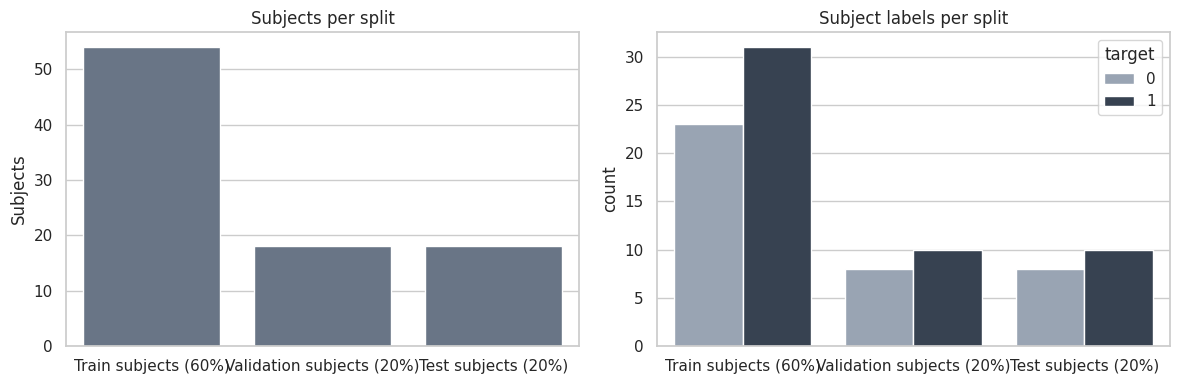

In [3]:
from sklearn.model_selection import train_test_split

subject_labels = df.groupby('subject_id', as_index=False).agg(target=('target', 'first'))
if df.groupby('subject_id')['target'].nunique().max() != 1:
    raise ValueError('A subject has inconsistent labels')

train_subjects, holdout_subjects = train_test_split(
    subject_labels,
    test_size=0.40,
    random_state=SPLIT_SEED,
    stratify=subject_labels['target'],
)
val_subjects, test_subjects = train_test_split(
    holdout_subjects,
    test_size=0.50,
    random_state=SPLIT_SEED,
    stratify=holdout_subjects['target'],
)
subject_sets = {
    'train': set(train_subjects['subject_id']),
    'val': set(val_subjects['subject_id']),
    'test': set(test_subjects['subject_id']),
}
assert not (subject_sets['train'] & subject_sets['val'])
assert not (subject_sets['train'] & subject_sets['test'])
assert not (subject_sets['val'] & subject_sets['test'])
assert set.union(*subject_sets.values()) == set(subject_labels['subject_id'])

split_frames = {
    part: df[df['subject_id'].isin(subjects)].reset_index(drop=True)
    for part, subjects in subject_sets.items()
}
split_summary = pd.DataFrame([
    {
        'Split': SPLIT_LABELS[part],
        'Subjects': frame['subject_id'].nunique(),
        'Events': frame['event_id'].nunique(),
        'Frames': len(frame),
        'Class 0 subjects': frame.groupby('subject_id')['target'].first().eq(0).sum(),
        'Class 1 subjects': frame.groupby('subject_id')['target'].first().eq(1).sum(),
        'Positive subject rate': frame.groupby('subject_id')['target'].first().mean(),
    }
    for part, frame in split_frames.items()
])
display(split_summary.style.hide(axis='index').format({'Positive subject rate': '{:.3f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=split_summary, x='Split', y='Subjects', ax=axes[0], color='#64748b')
axes[0].set(title='Subjects per split', xlabel='')
subject_distribution = pd.concat([
    frame.groupby('subject_id', as_index=False)['target'].first().assign(Split=SPLIT_LABELS[part])
    for part, frame in split_frames.items()
])
sns.countplot(data=subject_distribution, x='Split', hue='target', ax=axes[1], palette=['#94a3b8', '#334155'])
axes[1].set(title='Subject labels per split', xlabel='')
plt.tight_layout(); plt.show()


## 4. Export official TabR dataset
Imputer dan scaler di-fit hanya pada Train subjects (60%), lalu diterapkan ke Validation subjects (20%) dan Test subjects (20%). File split CSV dipertahankan untuk menghubungkan prediksi TabR kembali ke event dan subject. Sel ini aman dijalankan ulang dan hanya menulis artefak eksperimen bernama baru.

In [4]:
def export_official_dataset() -> pd.DataFrame:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    imputer = SimpleImputer(strategy='mean')
    scaler = StandardScaler()
    transformed = {}
    transformed['train'] = scaler.fit_transform(imputer.fit_transform(split_frames['train'][FEATURE_COLS])).astype(np.float32)
    for part in ('val', 'test'):
        transformed[part] = scaler.transform(imputer.transform(split_frames[part][FEATURE_COLS])).astype(np.float32)
    for part, part_df in split_frames.items():
        np.save(DATA_DIR / f'X_num_{part}.npy', transformed[part])
        np.save(DATA_DIR / f'Y_{part}.npy', part_df['target'].to_numpy(np.int64))
        part_df.to_csv(DATA_DIR / f'{part}_split.csv', index=False)
    (DATA_DIR / 'READY').write_text('')
    (DATA_DIR / 'info.json').write_text(json.dumps({'task_type': 'binclass', 'name': DATASET_NAME, 'id': DATASET_NAME}, indent=2))
    (DATA_DIR / 'feature_cols.json').write_text(json.dumps(FEATURE_COLS, indent=2))
    (DATA_DIR / 'preprocessing.json').write_text(json.dumps({
        'imputer': 'mean fitted on Train subjects only', 'scaler': 'StandardScaler fitted on Train subjects only',
        'feature_count': len(FEATURE_COLS), 'excluded_columns': META_COLS,
    }, indent=2))
    return pd.DataFrame([
        {'Split': SPLIT_LABELS[p], 'X shape': str(transformed[p].shape), 'X dtype': str(transformed[p].dtype), 'Y shape': str((len(split_frames[p]),)), 'Y dtype': 'int64'}
        for p in ('train', 'val', 'test')
    ])

export_table = export_official_dataset()
display(Markdown(f'**Official dataset ready:** `{DATA_DIR}`'))
display(export_table.style.hide(axis='index'))

**Official dataset ready:** `/home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/data/convat_opticalflow_behavioral_subject_independent`

Split,X shape,X dtype,Y shape,Y dtype
Train subjects (60%),"(9716, 47)",float32,"(9716,)",int64
Validation subjects (20%),"(3116, 47)",float32,"(3116,)",int64
Test subjects (20%),"(2705, 47)",float32,"(2705,)",int64


## 5. Siapkan tuning resmi TabR — 15 trials
Search space mengikuti konfigurasi resmi yang sudah dipakai repo: `context_size`, lebar model, dropout, jumlah block, learning rate, dan weight decay. `batch_size=128`, cache dataset, serta early stopping menjaga training stabil tanpa sengaja mengecilkan model.

In [5]:
def prepare_tuning_config() -> dict:
    config = copy.deepcopy(lib.load_config(BASE_TUNING_TOML))
    config['n_trials'] = N_TUNING_TRIALS
    config['space']['data']['path'] = f':data/{DATASET_NAME}'
    EXP_DIR.mkdir(parents=True, exist_ok=True)
    lib.dump_config(config, TUNING_TOML)
    return config

tuning_config = prepare_tuning_config()
display(Markdown(f'**Tuning config ready:** `{TUNING_TOML}`'))
display(pd.DataFrame([
    {'Setting': 'Trials', 'Value': tuning_config['n_trials']},
    {'Setting': 'Batch size', 'Value': tuning_config['space']['batch_size']},
    {'Setting': 'Patience', 'Value': tuning_config['space']['patience']},
    {'Setting': 'Context size search', 'Value': str(tuning_config['space']['context_size'])},
    {'Setting': 'Model width search', 'Value': str(tuning_config['space']['model']['d_main'])},
    {'Setting': 'Dataset', 'Value': tuning_config['space']['data']['path']},
]).style.hide(axis='index'))

**Tuning config ready:** `/home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/exp/tabr/convat_opticalflow_behavioral_subject_independent/0-tuning.toml`

Setting,Value
Trials,15
Batch size,128
Patience,6
Context size search,"['_tune_', 'int', 4, 16]"
Model width search,"['_tune_', 'int', 96, 256]"
Dataset,:data/convat_opticalflow_behavioral_subject_independent


## 6. Jalankan tuning, 15 evaluation seeds, dan 3 ensemble
Training berjalan otomatis saat artefak subject-independent belum ada. Setelah selesai, Run All berikutnya otomatis melewati training. Tuning dan early stopping hanya membaca Validation subjects.


In [6]:
# First Run All trains; subsequent Run All reuses completed artifacts.
if RUN_TRAINING:
    bin.go.main(
        TUNING_TOML,
        n_seeds=N_EVAL_SEEDS,
        n_ensembles=N_ENSEMBLES,
        ensemble_size=ENSEMBLE_SIZE,
        continue_=True,
        force=False,
    )
else:
    display(Markdown('> Training dilewati; memakai artefak eksperimen yang sudah tersedia.'))

2026-08-03 03:22:48.257 | INFO     | lib.util:start:130 - Creating the output


[>>>] exp/tabr/convat_opticalflow_behavioral_subject_independent/0-tuning | 2026-08-03 03:22:48.257171
--------------------------------------------------------------------------------
{'seed': 72,
 'function': 'bin.tabr.main',
 'space': {'seed': 72,
           'batch_size': 128,
           'patience': 6,
           'n_epochs': inf,
           'context_size': ['_tune_', 'int', 4, 16],
           'data': {'seed': 72,
                    'cache': True,
                    'path': ':data/convat_opticalflow_behavioral_subject_independent',
                    'num_policy': None,
                    'cat_policy': None,
                    'y_policy': None},
           'model': {'num_embeddings': None,
                     'd_main': ['_tune_', 'int', 96, 256],
                     'context_dropout': ['_tune_', 'uniform', 0.0, 0.35],
                     'd_multiplier': 2.0,
                     'encoder_n_blocks': ['_tune_', 'int', 0, 2],
                     'predictor_n_blocks': ['_tune_', 

[I 2026-08-03 03:22:48,545] A new study created in memory with name: no-name-a0b81e1c-d29d-426a-858a-1504e41a7717


  0%|          | 0/15 [00:00<?, ?it/s]

2026-08-03 03:22:48.552 | INFO     | lib.util:start:130 - Creating the output
2026-08-03 03:22:48.585 | INFO     | lib.data:build_dataset:346 - Building dataset (path: /home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/data/convat_opticalflow_behavioral_subject_independent)


...

(val) 0.575 (test) 0.779 (loss) 0.61981

[...] exp/tabr/convat_opticalflow_behavioral_subject_independent/0-evaluation/14 | 0:00:05.042420


Epoch 11: 100%|██████████| 76/76 [00:00<00:00, 193.61it/s]


(val) 0.575 (test) 0.779 (loss) 0.61919

[...] exp/tabr/convat_opticalflow_behavioral_subject_independent/0-evaluation/14 | 0:00:05.464311


Epoch 12: 100%|██████████| 76/76 [00:00<00:00, 191.88it/s]


(val) 0.575 (test) 0.778 (loss) 0.61868

--------------------------------------------------------------------------------
{'function': 'bin.tabr.main',
 'gpus': ['NVIDIA GeForce RTX 3050 Laptop GPU'],
 'n_parameters': 204796,
 'best_epoch': 5,
 'scores': {'train': 0.6799094277480444,
            'val': 0.5818356867779204,
            'test': 0.7811460258780037},
 'time': '0:00:05.889348'}
--------------------------------------------------------------------------------
[<<<] exp/tabr/convat_opticalflow_behavioral_subject_independent/0-evaluation/14 | 2026-08-03 03:26:54.438941

--------------------------------------------------------------------------------
{'function': 'bin.ensemble.main',
 'gpus': [],
 'scores': {'train': 0.6839234252778922,
            'val': 0.5789473684210527,
            'test': 0.7815157116451017}}
--------------------------------------------------------------------------------
[<<<] exp/tabr/convat_opticalflow_behavioral_subject_independent/0-ensemble-5/0 | 2026

## 7. Tuning summary dan trial ranking
Sel analisis berikut dapat dijalankan setelah training selesai. Ranking trial hanya menggunakan **Validation subjects (20%)** dari checkpoint Optuna. Test subjects (20%) tetap tertutup sampai konfigurasi dan model terkunci.

,Trial,Validation subjects (20%) accuracy,Best epoch,Parameters,Context,d_main,Encoder blocks,Predictor blocks,Learning rate,Weight decay
0,12,0.5870,3,204796,10,123,0,2,1.04e-05,4.95e-06
1,9,0.5844,8,143665,8,123,0,1,1.72e-05,3.12e-06
2,10,0.5834,17,147473,9,104,0,2,1.02e-05,7.94e-06
3,8,0.5825,0,294521,7,148,1,1,3.87e-04,1.19e-05
4,3,0.5825,13,485971,4,167,2,1,2.52e-05,2.24e-06
5,6,0.5818,1,758348,14,239,1,1,6.24e-05,2.58e-04
6,7,0.5812,7,533201,7,200,1,1,2.12e-04,8.10e-05
7,13,0.5809,0,228281,11,130,0,2,4.80e-05,4.34e-06
8,1,0.5806,2,364816,10,165,1,1,1.29e-04,1.29e-04
9,11,0.5793,10,144716,9,103,0,2,1.01e-05,8.56e-06


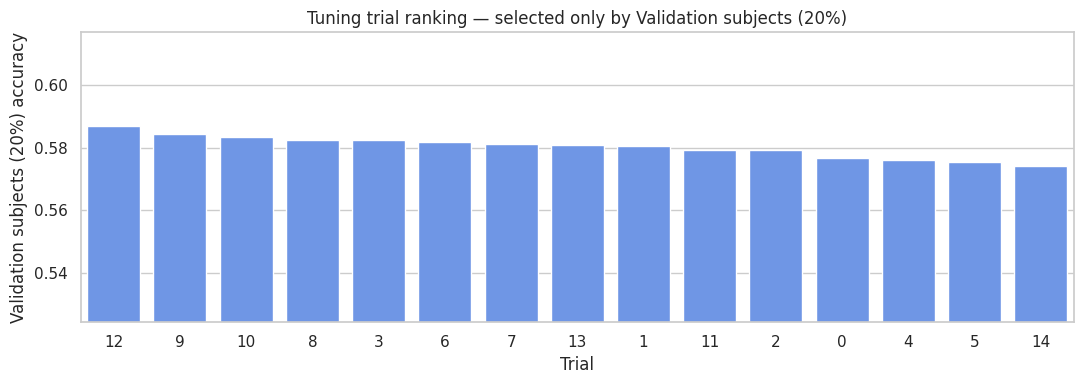

In [7]:
def require_artifact(path: Path, message: str) -> None:
    if not path.exists():
        raise FileNotFoundError(f'{message}: {path}')

require_artifact(EXP_DIR / '0-tuning' / 'checkpoint.pt', 'Run the training cell first')
tuning_checkpoint = lib.load_checkpoint(EXP_DIR / '0-tuning', map_location='cpu')
trial_rows = []
for report in tuning_checkpoint['trial_reports']:
    cfg = report['config']
    trial_rows.append({
        'Trial': report['trial_id'], 'Validation subjects (20%) accuracy': report['metrics']['val']['score'],
        'Best epoch': report['best_epoch'], 'Parameters': report['n_parameters'],
        'Context': cfg['context_size'], 'd_main': cfg['model']['d_main'],
        'Encoder blocks': cfg['model']['encoder_n_blocks'], 'Predictor blocks': cfg['model']['predictor_n_blocks'],
        'Learning rate': cfg['optimizer']['lr'], 'Weight decay': cfg['optimizer']['weight_decay'],
    })
trial_df = pd.DataFrame(trial_rows).sort_values('Validation subjects (20%) accuracy', ascending=False).reset_index(drop=True)
display(trial_df.style.format({'Validation subjects (20%) accuracy': '{:.4f}', 'Learning rate': '{:.2e}', 'Weight decay': '{:.2e}'}).background_gradient(subset=['Validation subjects (20%) accuracy'], cmap='Blues'))

plt.figure(figsize=(11, 4))
sns.barplot(data=trial_df, x='Trial', y='Validation subjects (20%) accuracy', color='#5b8ff9', order=trial_df['Trial'])
plt.title('Tuning trial ranking — selected only by Validation subjects (20%)')
plt.ylim(max(0, trial_df['Validation subjects (20%) accuracy'].min() - 0.05), min(1, trial_df['Validation subjects (20%) accuracy'].max() + 0.03))
plt.tight_layout()
plt.show()

## 8. Load predictions dan metric helpers
Prediksi single model tersimpan sebagai logits, sedangkan ensemble tersimpan sebagai probabilitas. Helper di bawah menormalisasi keduanya dan menyediakan evaluasi konsisten untuk semua split dan level.

In [8]:
def load_probabilities(run_dir: Path) -> dict[str, np.ndarray]:
    report = json.loads((run_dir / 'report.json').read_text())
    predictions = lib.load_predictions(run_dir)
    if report.get('prediction_type') == 'logits':
        return {part: expit(np.asarray(values)) for part, values in predictions.items()}
    return {part: np.asarray(values) for part, values in predictions.items()}

def metric_row(y_true: np.ndarray, prob: np.ndarray, threshold: float, level: str, part: str, source: str) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(prob, dtype=float)
    pred = (prob >= threshold).astype(int)
    both = len(np.unique(y_true)) == 2
    return {
        'Source': source, 'Level': level, 'Split': SPLIT_LABELS[part], 'N': len(y_true), 'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, pred), 'Balanced accuracy': balanced_accuracy_score(y_true, pred),
        'Macro-F1': f1_score(y_true, pred, average='macro', zero_division=0),
        'Weighted-F1': f1_score(y_true, pred, average='weighted', zero_division=0),
        'Precision class 1': precision_score(y_true, pred, zero_division=0),
        'Recall class 1': recall_score(y_true, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, prob) if both else np.nan,
        'PR-AUC': average_precision_score(y_true, prob) if both else np.nan,
    }

def aggregate_events(part_df: pd.DataFrame, prob: np.ndarray, method: str) -> pd.DataFrame:
    work = part_df[['event_id', 'subject_id', 'target', 'event_length', 'onset_frame', 'apex_frame', 'offset_frame']].copy()
    work['probability'] = prob
    def aggregate(values: pd.Series) -> float:
        arr = values.to_numpy(float)
        if method == 'mean': return float(arr.mean())
        if method == 'median': return float(np.median(arr))
        if method == 'max': return float(arr.max())
        if method == 'top3_mean': return float(np.sort(arr)[-min(3, len(arr)):].mean())
        raise ValueError(method)
    metadata = work.groupby('event_id', sort=False).agg({
        'subject_id': 'first', 'target': 'first', 'event_length': 'first',
        'onset_frame': 'first', 'apex_frame': 'first', 'offset_frame': 'first',
    })
    metadata['probability'] = work.groupby('event_id', sort=False)['probability'].apply(aggregate)
    return metadata.reset_index()

def aggregate_subjects(event_df: pd.DataFrame) -> pd.DataFrame:
    consistency = event_df.groupby('subject_id')['target'].nunique()
    if consistency.max() != 1:
        raise ValueError('A subject has inconsistent labels within a split')
    return event_df.groupby('subject_id', as_index=False).agg(target=('target', 'first'), probability=('probability', 'mean'), events=('event_id', 'size'))

def classification_report_table(y_true: np.ndarray, prob: np.ndarray, threshold: float) -> pd.DataFrame:
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(prob, dtype=float)
    pred = (prob >= threshold).astype(int)
    report = classification_report(y_true, pred, labels=[0, 1], output_dict=True, zero_division=0)
    rows = [{'': LABEL_NAMES[i], **report[str(i)]} for i in (0, 1)]
    rows.extend([
        {'': 'accuracy', 'precision': report['accuracy'], 'recall': report['accuracy'], 'f1-score': report['accuracy'], 'support': len(y_true)},
        {'': 'macro avg', **report['macro avg']},
        {'': 'weighted avg', **report['weighted avg']},
        {'': 'cross-entropy', 'precision': log_loss(y_true, prob, labels=[0, 1]), 'recall': np.nan, 'f1-score': np.nan, 'support': np.nan},
        {'': 'roc-auc', 'precision': roc_auc_score(y_true, prob), 'recall': np.nan, 'f1-score': np.nan, 'support': np.nan},
        {'': 'score', 'precision': report['accuracy'], 'recall': np.nan, 'f1-score': np.nan, 'support': np.nan},
    ])
    return pd.DataFrame(rows).set_index('')

def display_reports_one_row(level: str, level_data: dict) -> None:
    threshold = 0.5 if level == 'Frame' else SELECTED_THRESHOLD
    panels = []
    for part in ('train', 'val', 'test'):
        data = level_data[(part, level)]
        y = data['target'].to_numpy(int)
        prob = data['probability'].to_numpy(float)
        pred = (prob >= threshold).astype(int)
        report = classification_report(y, pred, labels=[0, 1], output_dict=True, zero_division=0)
        rows = [
            ('0', report['0']['precision'], report['0']['recall'], report['0']['f1-score'], int(report['0']['support'])),
            ('1', report['1']['precision'], report['1']['recall'], report['1']['f1-score'], int(report['1']['support'])),
            ('accuracy', report['accuracy'], report['accuracy'], report['accuracy'], len(y)),
            ('macro avg', report['macro avg']['precision'], report['macro avg']['recall'], report['macro avg']['f1-score'], len(y)),
            ('weighted avg', report['weighted avg']['precision'], report['weighted avg']['recall'], report['weighted avg']['f1-score'], len(y)),
            ('cross-entropy', log_loss(y, prob, labels=[0, 1]), None, None, None),
            ('roc-auc', roc_auc_score(y, prob), None, None, None),
            ('score', report['accuracy'], None, None, None),
        ]
        fmt = lambda value: '—' if value is None else f'{value:.4f}'
        body = ''.join(
            f"<tr><th>{name}</th><td>{fmt(precision)}</td><td>{fmt(recall)}</td>"
            f"<td>{fmt(f1)}</td><td>{'—' if support is None else f'{support:,}'}</td></tr>"
            for name, precision, recall, f1, support in rows
        )
        panels.append(f"""<div class='cr-panel'><div class='cr-title'>{SPLIT_LABELS[part]}</div>
        <table><thead><tr><th></th><th>precision</th><th>recall</th><th>f1-score</th><th>support</th></tr></thead>
        <tbody>{body}</tbody></table></div>""")
    css = """<style>
      .cr-row{display:flex;gap:18px;width:100%;overflow-x:auto;padding:2px 0 8px;font-family:Arial,sans-serif;color:#3f4775}
      .cr-panel{flex:1 0 390px;max-width:430px}
      .cr-title{text-align:center;font-size:13px;font-weight:700;padding:7px 0;color:#454d78}
      .cr-panel table{width:100%;border-collapse:collapse;font-size:12px;font-variant-numeric:tabular-nums}
      .cr-panel th,.cr-panel td{padding:6px 8px;text-align:right;white-space:nowrap}
      .cr-panel thead th{background:#e7e3e3;font-weight:700}
      .cr-panel tbody th{font-weight:400;text-align:right;width:105px}
      .cr-panel tbody tr:nth-child(odd){background:#f3efef}
      .cr-panel tbody tr:nth-child(even){background:#ebe7e7}
    </style>"""
    display(HTML(css + "<div class='cr-row'>" + ''.join(panels) + '</div>'))

def select_event_rule(part_df: pd.DataFrame, prob: np.ndarray) -> tuple[pd.DataFrame, dict]:
    rows = []
    thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
    for method in ('mean', 'median', 'max', 'top3_mean'):
        event_df = aggregate_events(part_df, prob, method)
        for threshold in thresholds:
            row = metric_row(event_df['target'].to_numpy(), event_df['probability'].to_numpy(), threshold, 'Event', 'val', method)
            rows.append(row)
    search = pd.DataFrame(rows)
    search['Distance to 0.5'] = (search['Threshold'] - 0.5).abs()
    best = search.sort_values(['Macro-F1', 'Balanced accuracy', 'Distance to 0.5'], ascending=[False, False, True]).iloc[0].to_dict()
    return search, best

## 9. Seed stability dan best-seed selection
Setiap seed dievaluasi dengan rule event yang dipilih hanya pada Validation subjects (20%). Best seed juga dipilih dari Validation subjects (20%). Tabel dan boxplot menunjukkan stabilitas, termasuk mean ± standard deviation wajib.

### Best seed selected by Validation subjects (20%): **13**

Split,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std
Test subjects (20%),0.5081,0.0958,0.5360,0.0786,0.5970,0.1356
Train subjects (60%),0.5674,0.0790,0.5811,0.0717,0.6103,0.0898
Validation subjects (20%),0.5341,0.0436,0.5439,0.0448,0.5539,0.0453


,Seed,Split,Aggregation,Threshold,Accuracy,Balanced accuracy,Macro-F1,ROC-AUC,PR-AUC
0,0,Train subjects (60%),mean,0.6600,0.7406,0.6588,0.6686,0.7996,0.8790
1,0,Validation subjects (20%),mean,0.6600,0.5639,0.5307,0.5181,0.4134,0.5201
2,0,Test subjects (20%),mean,0.6600,0.8000,0.6468,0.6639,0.6410,0.8162
3,1,Train subjects (60%),max,0.7800,0.5611,0.5534,0.5424,0.5808,0.7074
4,1,Validation subjects (20%),max,0.7800,0.5489,0.5461,0.5445,0.5753,0.6518
5,1,Test subjects (20%),max,0.7800,0.5545,0.5199,0.4905,0.5000,0.7848
6,2,Train subjects (60%),median,0.6900,0.6833,0.6369,0.6393,0.6694,0.7722
7,2,Validation subjects (20%),median,0.6900,0.5714,0.5439,0.5375,0.5016,0.5833
8,2,Test subjects (20%),median,0.6900,0.6182,0.5455,0.5284,0.5436,0.7781
9,3,Train subjects (60%),median,0.6700,0.6484,0.6123,0.6112,0.6591,0.7595


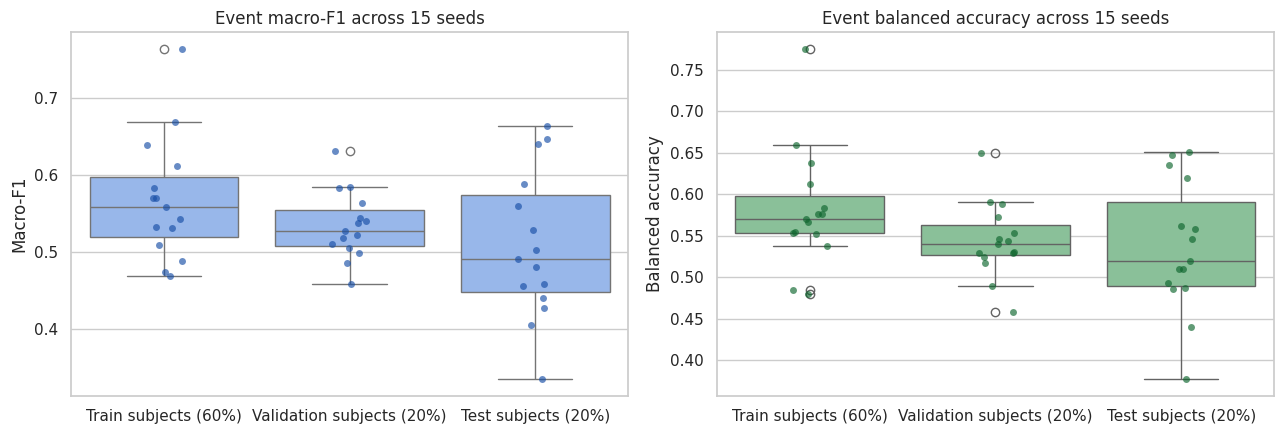

In [9]:
require_artifact(EVAL_DIR, 'Evaluation outputs are missing')
seed_rows = []
seed_rules = {}
for seed in range(N_EVAL_SEEDS):
    run_dir = EVAL_DIR / str(seed)
    require_artifact(run_dir / 'DONE', f'Seed {seed} is incomplete')
    probs = load_probabilities(run_dir)
    _, rule = select_event_rule(split_frames['val'], probs['val'])
    seed_rules[seed] = rule
    for part in ('train', 'val', 'test'):
        events = aggregate_events(split_frames[part], probs[part], rule['Source'])
        row = metric_row(events['target'].to_numpy(), events['probability'].to_numpy(), rule['Threshold'], 'Event', part, f'Seed {seed}')
        row['Seed'] = seed
        row['Aggregation'] = rule['Source']
        seed_rows.append(row)
seed_metrics = pd.DataFrame(seed_rows)
best_seed = int(seed_metrics[seed_metrics['Split'] == SPLIT_LABELS['val']].sort_values(['Macro-F1', 'Balanced accuracy'], ascending=False).iloc[0]['Seed'])
stability = seed_metrics.groupby('Split').agg(
    macro_f1_mean=('Macro-F1', 'mean'), macro_f1_std=('Macro-F1', 'std'),
    balanced_accuracy_mean=('Balanced accuracy', 'mean'), balanced_accuracy_std=('Balanced accuracy', 'std'),
    accuracy_mean=('Accuracy', 'mean'), accuracy_std=('Accuracy', 'std'),
).reset_index()
display(Markdown(f'### Best seed selected by Validation subjects (20%): **{best_seed}**'))
display(stability.style.hide(axis='index').format({c: '{:.4f}' for c in stability.columns if c != 'Split'}))
display(seed_metrics[['Seed', 'Split', 'Aggregation', 'Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']].style.format({c: '{:.4f}' for c in ['Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=seed_metrics, x='Split', y='Macro-F1', ax=axes[0], color='#8ab4f8')
sns.stripplot(data=seed_metrics, x='Split', y='Macro-F1', ax=axes[0], color='#174ea6', alpha=.65)
axes[0].set(title='Event macro-F1 across 15 seeds', xlabel='')
sns.boxplot(data=seed_metrics, x='Split', y='Balanced accuracy', ax=axes[1], color='#81c995')
sns.stripplot(data=seed_metrics, x='Split', y='Balanced accuracy', ax=axes[1], color='#0d652d', alpha=.65)
axes[1].set(title='Event balanced accuracy across 15 seeds', xlabel='')
plt.tight_layout()
plt.show()

## 10. Training curves — Train vs Validation
Official checkpoint mencatat train loss setiap epoch serta validation loss/accuracy. Best epoch ditentukan oleh validation performance. Test curve sengaja tidak dipakai untuk memilih epoch.

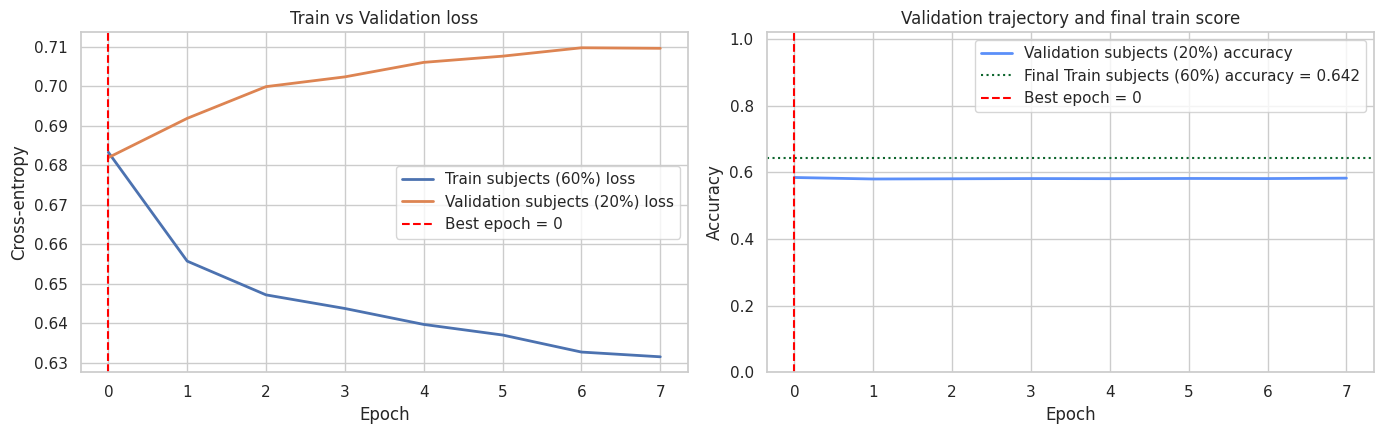

Best seed,Best epoch,Parameters,Training time
13,0,204796,0:00:03.508486


In [10]:
best_run_dir = EVAL_DIR / str(best_seed)
checkpoint = lib.load_checkpoint(best_run_dir, map_location='cpu')
best_report = json.loads((best_run_dir / 'report.json').read_text())
curve_rows = []
for epoch, item in enumerate(checkpoint['training_log']):
    metrics = item['metrics']
    epoch_losses = item.get('epoch-losses', [])
    curve_rows.append({
        'Epoch': epoch,
        'Train loss': float(np.mean(epoch_losses)) if len(epoch_losses) else np.nan,
        'Validation loss': float(metrics['val'].get('cross-entropy', np.nan)),
        'Validation accuracy': float(metrics['val']['score']),
    })
curve_df = pd.DataFrame(curve_rows)
best_epoch = int(best_report['best_epoch'])
final_train_accuracy = float(best_report['metrics']['train']['score'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(curve_df['Epoch'], curve_df['Train loss'], label='Train subjects (60%) loss', linewidth=2)
axes[0].plot(curve_df['Epoch'], curve_df['Validation loss'], label='Validation subjects (20%) loss', linewidth=2)
axes[0].axvline(best_epoch, color='red', linestyle='--', label=f'Best epoch = {best_epoch}')
axes[0].set(title='Train vs Validation loss', xlabel='Epoch', ylabel='Cross-entropy')
axes[0].legend()
axes[1].plot(curve_df['Epoch'], curve_df['Validation accuracy'], label='Validation subjects (20%) accuracy', linewidth=2, color='#5b8ff9')
axes[1].axhline(final_train_accuracy, color='#0d652d', linestyle=':', label=f'Final Train subjects (60%) accuracy = {final_train_accuracy:.3f}')
axes[1].axvline(best_epoch, color='red', linestyle='--', label=f'Best epoch = {best_epoch}')
axes[1].set(title='Validation trajectory and final train score', xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1.02))
axes[1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame([{'Best seed': best_seed, 'Best epoch': best_epoch, 'Parameters': best_report['n_parameters'], 'Training time': best_report['time']}]).style.hide(axis='index'))

## 11. Validation-only aggregation dan threshold selection
Empat aggregation rule dibandingkan pada Validation subjects (20%): `mean`, `median`, `max`, dan `top3_mean`. Rule dipilih berdasarkan macro-F1, lalu balanced accuracy, lalu threshold terdekat 0.5. Setelah sel ini, rule dikunci untuk Train subjects (60%) dan Test subjects (20%).

### Locked rule: **max**, threshold **0.72** — selected only on Validation subjects (20%)

Aggregation,Threshold,Accuracy,Balanced accuracy,Macro-F1,ROC-AUC,PR-AUC
max,0.7200,0.6316,0.6491,0.6312,0.6678,0.7302
top3_mean,0.6900,0.6391,0.6294,0.6299,0.6450,0.7316
mean,0.6000,0.6391,0.6272,0.6280,0.6768,0.7032
median,0.6000,0.6090,0.5921,0.5922,0.6152,0.6893


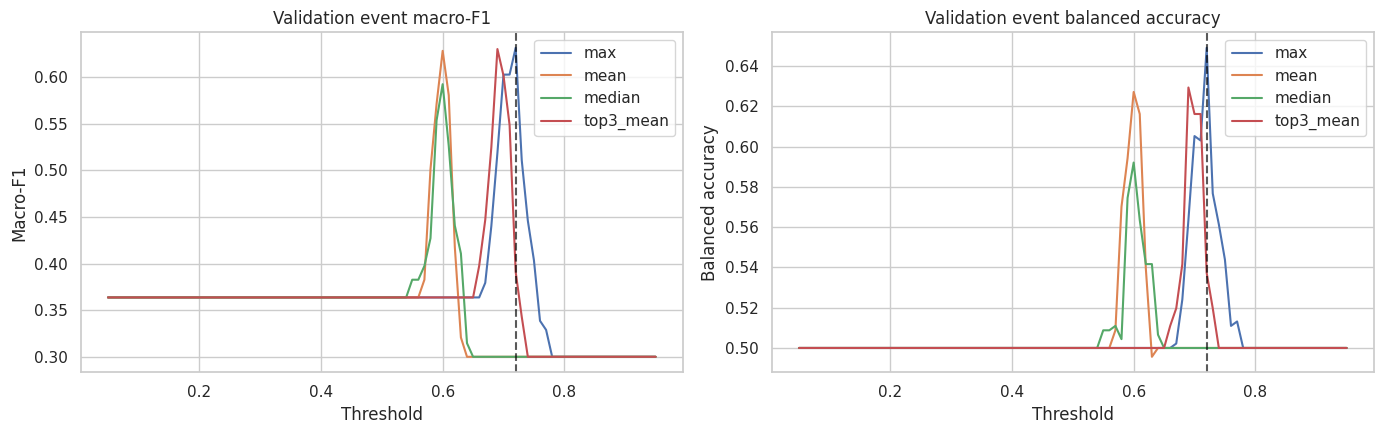

In [11]:
best_probs = load_probabilities(best_run_dir)
assert all(len(best_probs[p]) == len(split_frames[p]) for p in ('train', 'val', 'test'))
rule_search, selected_rule = select_event_rule(split_frames['val'], best_probs['val'])
SELECTED_AGGREGATION = selected_rule['Source']
SELECTED_THRESHOLD = float(selected_rule['Threshold'])
aggregation_best = (rule_search.sort_values(['Macro-F1', 'Balanced accuracy'], ascending=False).groupby('Source', as_index=False).first().sort_values('Macro-F1', ascending=False))
display(Markdown(f'### Locked rule: **{SELECTED_AGGREGATION}**, threshold **{SELECTED_THRESHOLD:.2f}** — selected only on Validation subjects (20%)'))
display(aggregation_best[['Source', 'Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']].rename(columns={'Source': 'Aggregation'}).style.hide(axis='index').format({c: '{:.4f}' for c in ['Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']}).background_gradient(subset=['Macro-F1'], cmap='Blues'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for method, group in rule_search.groupby('Source'):
    axes[0].plot(group['Threshold'], group['Macro-F1'], label=method)
    axes[1].plot(group['Threshold'], group['Balanced accuracy'], label=method)
for ax, title, ylabel in zip(axes, ['Validation event macro-F1', 'Validation event balanced accuracy'], ['Macro-F1', 'Balanced accuracy']):
    ax.axvline(SELECTED_THRESHOLD, color='black', linestyle='--', alpha=.65)
    ax.set(title=title, xlabel='Threshold', ylabel=ylabel)
    ax.legend()
plt.tight_layout()
plt.show()

## 12. Frame, event, dan subject metrics — semua split
Semua tabel memakai nama split eksplisit. Frame-level memakai threshold 0.5 bawaan classifier. Event dan subject memakai aggregation serta threshold yang sudah dikunci dari Validation subjects (20%).

In [12]:
level_data = {}
metric_rows = []
for part in ('train', 'val', 'test'):
    frame = split_frames[part][['event_id', 'subject_id', 'target']].copy()
    frame['probability'] = best_probs[part]
    event = aggregate_events(split_frames[part], best_probs[part], SELECTED_AGGREGATION)
    subject = aggregate_subjects(event)
    level_data[(part, 'Frame')] = frame
    level_data[(part, 'Event')] = event
    level_data[(part, 'Subject')] = subject
    metric_rows.append(metric_row(frame['target'].to_numpy(), frame['probability'].to_numpy(), 0.5, 'Frame', part, f'Best seed {best_seed}'))
    metric_rows.append(metric_row(event['target'].to_numpy(), event['probability'].to_numpy(), SELECTED_THRESHOLD, 'Event', part, f'Best seed {best_seed}'))
    metric_rows.append(metric_row(subject['target'].to_numpy(), subject['probability'].to_numpy(), SELECTED_THRESHOLD, 'Subject', part, f'Best seed {best_seed}'))
all_metrics = pd.DataFrame(metric_rows)
metric_columns = ['Level', 'Split', 'N', 'Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'Weighted-F1', 'Precision class 1', 'Recall class 1', 'ROC-AUC', 'PR-AUC']
display(all_metrics[metric_columns].style.hide(axis='index').format({c: '{:.4f}' for c in metric_columns if c not in {'Level', 'Split', 'N'}}).background_gradient(subset=['Macro-F1', 'Balanced accuracy'], cmap='Blues'))

for level in ('Frame', 'Event', 'Subject'):
    display(Markdown(f'### {level}-level classification reports'))
    display_reports_one_row(level, level_data)

Level,Split,N,Threshold,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1,Precision class 1,Recall class 1,ROC-AUC,PR-AUC
Frame,Train subjects (60%),9716,0.5000,0.6418,0.4951,0.4274,0.5414,0.6604,0.9460,0.4624,0.6358
Event,Train subjects (60%),401,0.7200,0.4988,0.4794,0.4746,0.5108,0.6441,0.5396,0.4712,0.6551
Subject,Train subjects (60%),54,0.7200,0.5185,0.4965,0.4935,0.5102,0.5714,0.6452,0.3927,0.4925
Frame,Validation subjects (20%),3116,0.5000,0.5844,0.5160,0.4302,0.4762,0.5860,0.9561,0.5341,0.6055
Event,Validation subjects (20%),133,0.7200,0.6316,0.6491,0.6312,0.6297,0.7547,0.5263,0.6678,0.7302
Subject,Validation subjects (20%),18,0.7200,0.6667,0.6875,0.6625,0.6583,0.8333,0.5000,0.7125,0.7665
Frame,Test subjects (20%),2705,0.5000,0.7320,0.4885,0.4575,0.6699,0.7709,0.9309,0.4853,0.7629
Event,Test subjects (20%),110,0.7200,0.3545,0.3769,0.3347,0.3995,0.6744,0.3372,0.3542,0.7308
Subject,Test subjects (20%),18,0.7200,0.3333,0.3375,0.3333,0.3333,0.3750,0.3000,0.2125,0.4490


### Frame-level classification reports

,precision,recall,f1-score,support
0,0.2941,0.0442,0.0769,"3,277"
1,0.6604,0.9460,0.7778,"6,439"
accuracy,0.6418,0.6418,0.6418,"9,716"
macro avg,0.4773,0.4951,0.4274,"9,716"
weighted avg,0.5369,0.6418,0.5414,"9,716"
cross-entropy,0.6622,—,—,—
roc-auc,0.4624,—,—,—
score,0.6418,—,—,—
,precision,recall,f1-score,support
0,0.5587,0.0760,0.1338,"1,316"


### Event-level classification reports

,precision,recall,f1-score,support
0,0.3184,0.4191,0.3619,136
1,0.6441,0.5396,0.5873,265
accuracy,0.4988,0.4988,0.4988,401
macro avg,0.4813,0.4794,0.4746,401
weighted avg,0.5337,0.4988,0.5108,401
cross-entropy,0.6545,—,—,—
roc-auc,0.4712,—,—,—
score,0.4988,—,—,—
,precision,recall,f1-score,support
0,0.5500,0.7719,0.6423,57


### Subject-level classification reports

,precision,recall,f1-score,support
0,0.4211,0.3478,0.3810,23
1,0.5714,0.6452,0.6061,31
accuracy,0.5185,0.5185,0.5185,54
macro avg,0.4962,0.4965,0.4935,54
weighted avg,0.5074,0.5185,0.5102,54
cross-entropy,0.7386,—,—,—
roc-auc,0.3927,—,—,—
score,0.5185,—,—,—
,precision,recall,f1-score,support
0,0.5833,0.8750,0.7000,8


## 13. Confusion matrices, ROC, dan Precision–Recall
Setiap baris visual menampilkan Train subjects (60%), Validation subjects (20%), dan Test subjects (20%) berdampingan.

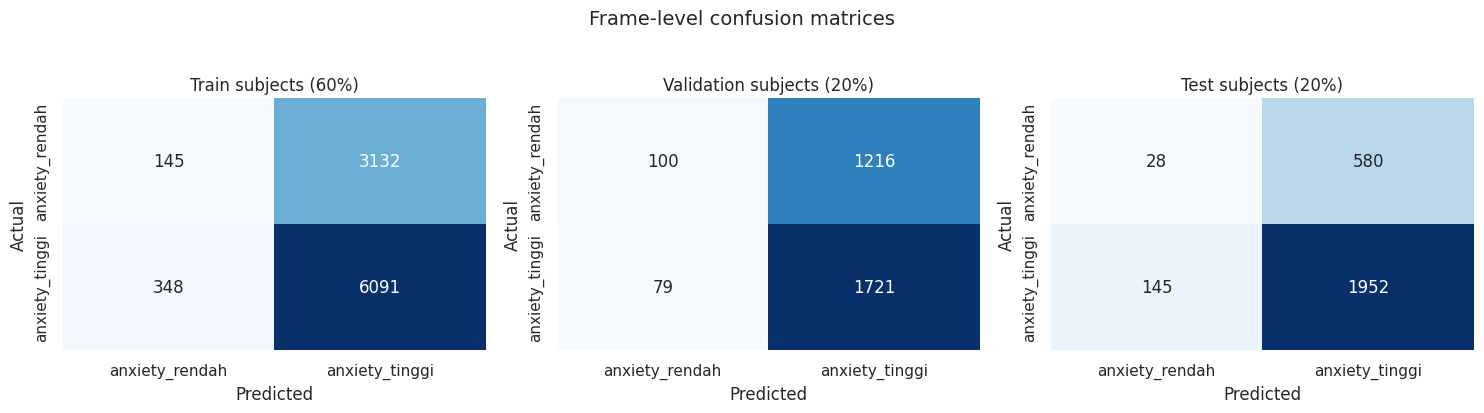

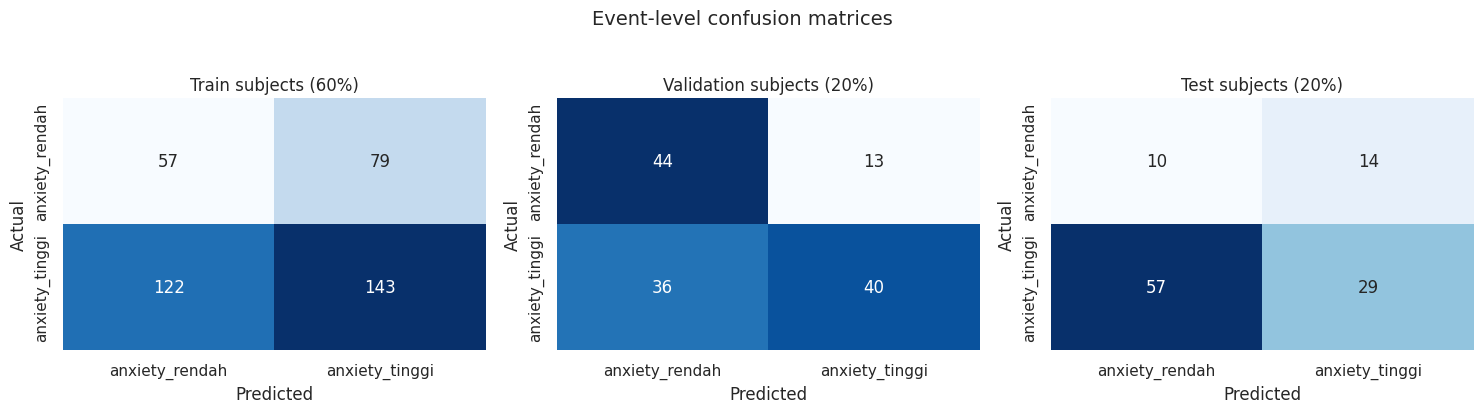

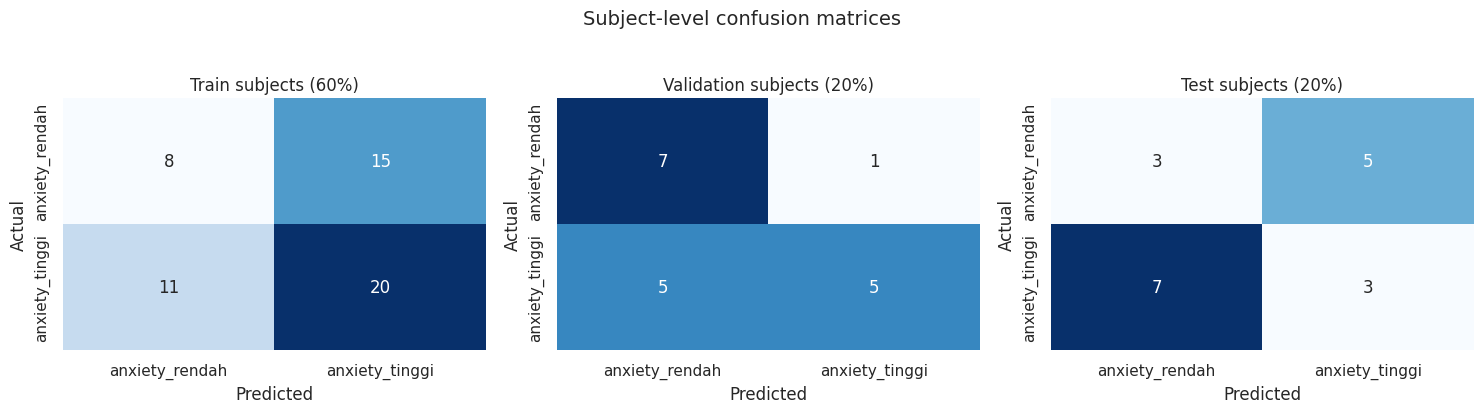

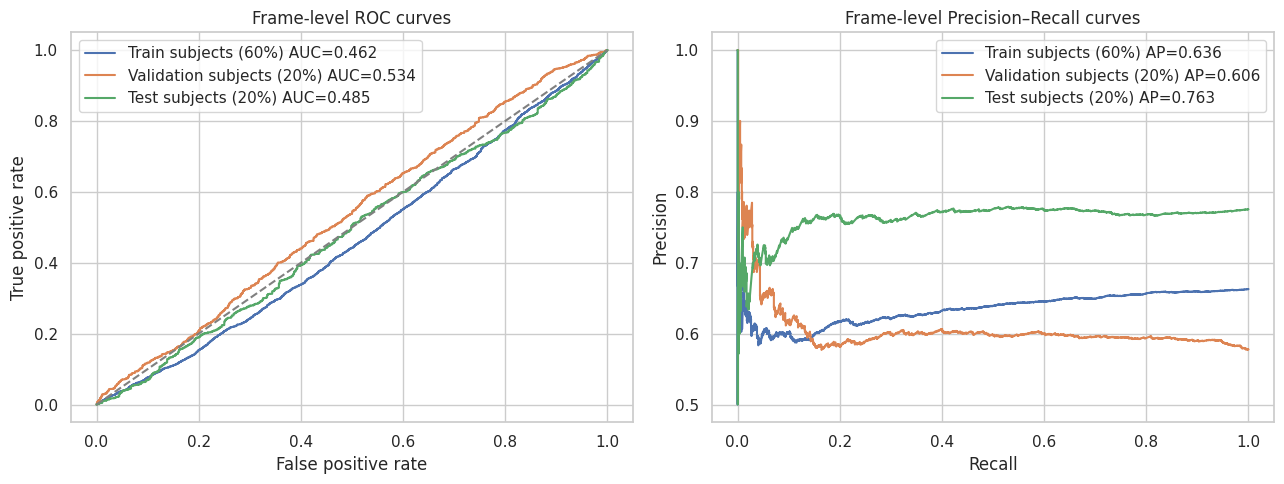

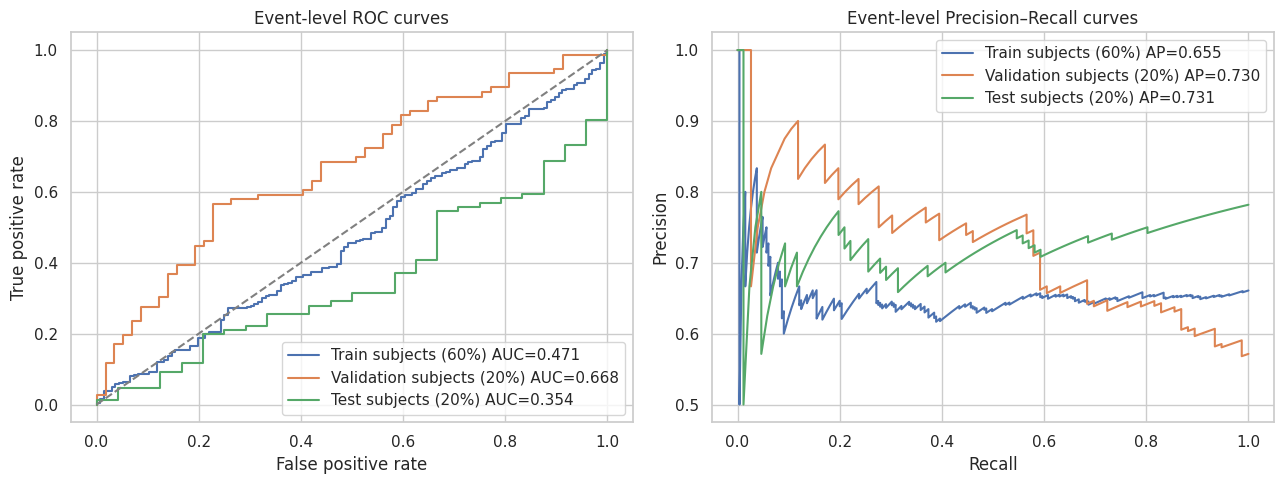

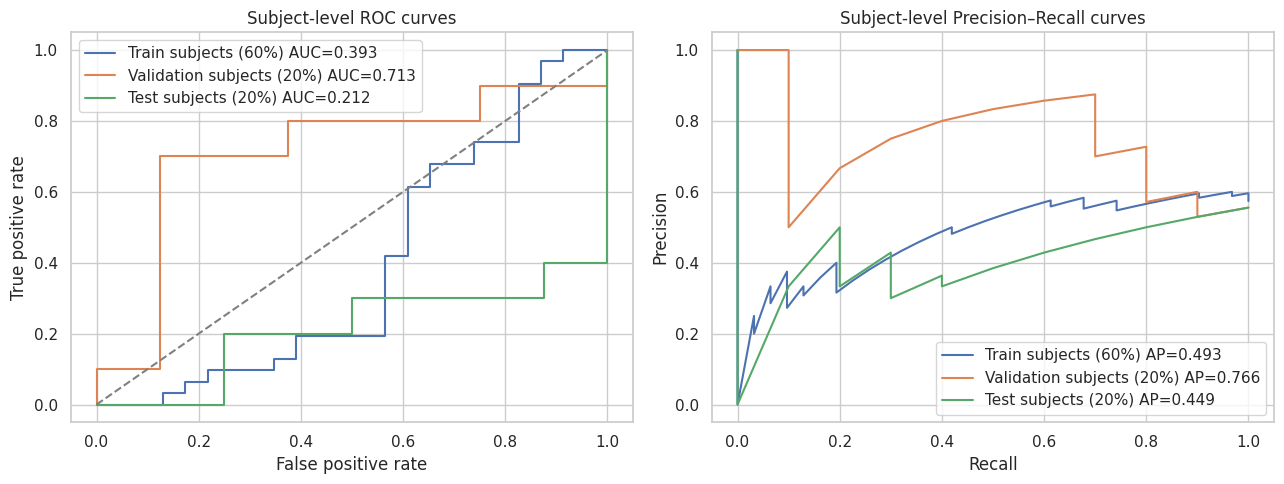

In [13]:
for level in ('Frame', 'Event', 'Subject'):
    threshold = 0.5 if level == 'Frame' else SELECTED_THRESHOLD
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, part in zip(axes, ('train', 'val', 'test')):
        data = level_data[(part, level)]
        pred = (data['probability'].to_numpy() >= threshold).astype(int)
        cm = confusion_matrix(data['target'], pred, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
        ax.set(title=SPLIT_LABELS[part], xlabel='Predicted', ylabel='Actual')
    fig.suptitle(f'{level}-level confusion matrices', fontsize=14, y=1.03)
    plt.tight_layout()
    plt.show()

for level in ('Frame', 'Event', 'Subject'):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for part in ('train', 'val', 'test'):
        data = level_data[(part, level)]
        y = data['target'].to_numpy()
        p = data['probability'].to_numpy()
        fpr, tpr, _ = roc_curve(y, p)
        precision, recall, _ = precision_recall_curve(y, p)
        axes[0].plot(fpr, tpr, label=f"{SPLIT_LABELS[part]} AUC={roc_auc_score(y, p):.3f}")
        axes[1].plot(recall, precision, label=f"{SPLIT_LABELS[part]} AP={average_precision_score(y, p):.3f}")
    axes[0].plot([0, 1], [0, 1], '--', color='gray')
    axes[0].set(title=f'{level}-level ROC curves', xlabel='False positive rate', ylabel='True positive rate')
    axes[1].set(title=f'{level}-level Precision–Recall curves', xlabel='Recall', ylabel='Precision')
    axes[0].legend(); axes[1].legend()
    plt.tight_layout()
    plt.show()

## 14. Ensemble comparison
Tiga ensemble dibandingkan menggunakan rule yang dipilih pada Validation subjects (20%) masing-masing. Best ensemble dipilih dari Validation subjects (20%); hasil Test subjects (20%) tetap hanya evaluasi terkunci.

### Best ensemble selected by Validation subjects (20%): **Ensemble 2**

Ensemble,Split,Aggregation,Threshold,Accuracy,Balanced accuracy,Macro-F1,ROC-AUC,PR-AUC
0,Validation subjects (20%),median,0.6900,0.5113,0.4912,0.4886,0.4490,0.5373
0,Test subjects (20%),median,0.6900,0.7000,0.5828,0.5788,0.6231,0.8134
1,Validation subjects (20%),top3_mean,0.7200,0.5639,0.5241,0.5017,0.4645,0.5656
1,Test subjects (20%),top3_mean,0.7200,0.6727,0.5354,0.5341,0.4748,0.7494
2,Validation subjects (20%),mean,0.6600,0.5414,0.5241,0.5231,0.5212,0.5884
2,Test subjects (20%),mean,0.6600,0.7818,0.6652,0.6702,0.6744,0.8580


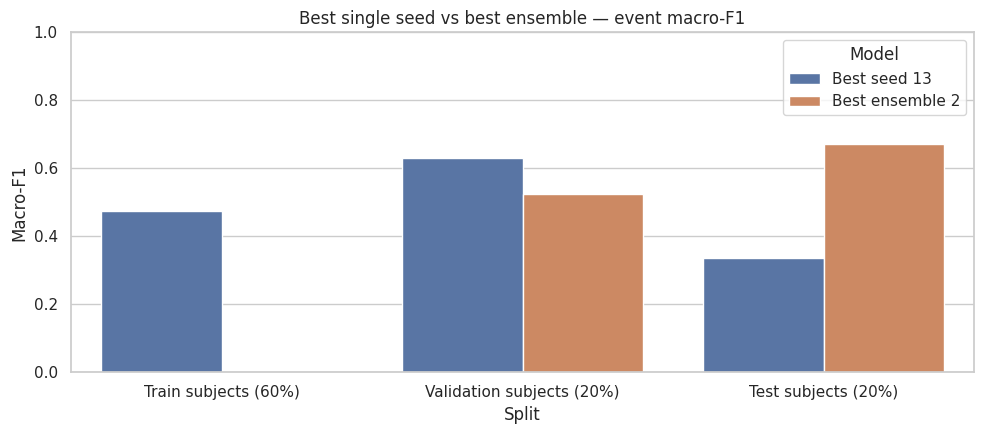

In [14]:
ensemble_rows = []
ensemble_rules = {}
if ENSEMBLE_DIR.exists():
    for ensemble_id in range(N_ENSEMBLES):
        run_dir = ENSEMBLE_DIR / str(ensemble_id)
        if not (run_dir / 'DONE').exists():
            continue
        probs = load_probabilities(run_dir)
        _, rule = select_event_rule(split_frames['val'], probs['val'])
        ensemble_rules[ensemble_id] = rule
        for part in ('val', 'test'):
            events = aggregate_events(split_frames[part], probs[part], rule['Source'])
            row = metric_row(events['target'].to_numpy(), events['probability'].to_numpy(), rule['Threshold'], 'Event', part, f'Ensemble {ensemble_id}')
            row['Ensemble'] = ensemble_id
            row['Aggregation'] = rule['Source']
            ensemble_rows.append(row)
ensemble_metrics = pd.DataFrame(ensemble_rows)
if ensemble_metrics.empty:
    display(Markdown('> Ensemble belum tersedia. Selesaikan training cell terlebih dahulu.'))
else:
    best_ensemble = int(ensemble_metrics[ensemble_metrics['Split'] == SPLIT_LABELS['val']].sort_values(['Macro-F1', 'Balanced accuracy'], ascending=False).iloc[0]['Ensemble'])
    display(Markdown(f'### Best ensemble selected by Validation subjects (20%): **Ensemble {best_ensemble}**'))
    display(ensemble_metrics[['Ensemble', 'Split', 'Aggregation', 'Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']].style.hide(axis='index').format({c: '{:.4f}' for c in ['Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']}))
    comparison = pd.concat([
        seed_metrics[seed_metrics['Seed'] == best_seed].assign(Model=f'Best seed {best_seed}'),
        ensemble_metrics[ensemble_metrics['Ensemble'] == best_ensemble].assign(Model=f'Best ensemble {best_ensemble}'),
    ], ignore_index=True)
    plt.figure(figsize=(10, 4.5))
    sns.barplot(data=comparison, x='Split', y='Macro-F1', hue='Model')
    plt.title('Best single seed vs best ensemble — event macro-F1')
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

## 15. Error analysis dan final artifacts
False positive dan false negative event ditampilkan untuk Validation subjects (20%) dan Test subjects (20%), lengkap dengan subject, confidence, panjang event, serta onset/apex/offset. Semua tabel utama disimpan agar laporan dapat dibuka tanpa menjalankan ulang training.

In [15]:
error_tables = {}
for part in ('val', 'test'):
    errors = level_data[(part, 'Event')].copy()
    errors['prediction'] = (errors['probability'] >= SELECTED_THRESHOLD).astype(int)
    errors['error_type'] = np.select(
        [(errors['target'] == 0) & (errors['prediction'] == 1), (errors['target'] == 1) & (errors['prediction'] == 0)],
        ['False positive', 'False negative'], default='Correct',
    )
    errors['confidence'] = np.where(errors['prediction'] == 1, errors['probability'], 1 - errors['probability'])
    errors = errors[errors['error_type'] != 'Correct'].sort_values('confidence', ascending=False)
    error_tables[part] = errors
    display(Markdown(f"### {SPLIT_LABELS[part]} event errors — {len(errors)} / {len(level_data[(part, 'Event')])}"))
    display(errors[['event_id', 'subject_id', 'target', 'prediction', 'error_type', 'probability', 'confidence', 'event_length', 'onset_frame', 'apex_frame', 'offset_frame']].style.hide(axis='index').format({'probability': '{:.4f}', 'confidence': '{:.4f}'}))

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
split_summary.to_csv(ARTIFACT_DIR / 'split_summary.csv', index=False)
trial_df.to_csv(ARTIFACT_DIR / 'tuning_trials.csv', index=False)
seed_metrics.to_csv(ARTIFACT_DIR / 'seed_stability.csv', index=False)
stability.to_csv(ARTIFACT_DIR / 'seed_mean_std.csv', index=False)
all_metrics.to_csv(ARTIFACT_DIR / 'best_seed_all_level_metrics.csv', index=False)
aggregation_best.to_csv(ARTIFACT_DIR / 'validation_aggregation_comparison.csv', index=False)
for part, errors in error_tables.items():
    errors.to_csv(ARTIFACT_DIR / f'{part}_event_errors.csv', index=False)
if not ensemble_metrics.empty:
    ensemble_metrics.to_csv(ARTIFACT_DIR / 'ensemble_comparison.csv', index=False)
final_manifest = {
    'split_seed': SPLIT_SEED,
    'split_subjects': {part: sorted(subjects) for part, subjects in subject_sets.items()},
    'best_seed_selected_on_validation': best_seed,
    'event_aggregation_selected_on_validation': SELECTED_AGGREGATION,
    'event_threshold_selected_on_validation': SELECTED_THRESHOLD,
    'feature_count': len(FEATURE_COLS), 'features': FEATURE_COLS,
}
(ARTIFACT_DIR / 'manifest.json').write_text(json.dumps(final_manifest, indent=2))
display(Markdown(f'## Analysis artifacts saved to `{ARTIFACT_DIR}`'))
display(all_metrics[metric_columns].style.hide(axis='index').format({c: '{:.4f}' for c in metric_columns if c not in {'Level', 'Split', 'N'}}).background_gradient(subset=['Macro-F1', 'Balanced accuracy'], cmap='Greens'))

### Validation subjects (20%) event errors — 49 / 133

event_id,subject_id,target,prediction,error_type,probability,confidence,event_length,onset_frame,apex_frame,offset_frame
aida_rahma_fadhila_after_q2_event_1,aida_rahma_fadhila_after,0,1,False positive,0.7673,0.7673,26,61,73,87
fiera_ziadattun_nisa_before_q5_event_0,fiera_ziadattun_nisa_before,0,1,False positive,0.7461,0.7461,23,6,16,29
muhammad_syahrul_gunawan_after_q2_event_1,muhammad_syahrul_gunawan_after,0,1,False positive,0.7371,0.7371,26,18,30,44
muhammad_zaki_after_q2_event_0,muhammad_zaki_after,0,1,False positive,0.7365,0.7365,29,52,62,81
fiera_ziadattun_nisa_before_q2_event_0,fiera_ziadattun_nisa_before,0,1,False positive,0.7347,0.7347,22,6,17,28
aida_rahma_fadhila_after_q2_event_0,aida_rahma_fadhila_after,0,1,False positive,0.7321,0.7321,16,0,4,16
rafiqo_adib_destarachmad_before_q3_event_0,rafiqo_adib_destarachmad_before,0,1,False positive,0.7313,0.7313,20,89,98,109
fiera_ziadattun_nisa_before_q1_event_0,fiera_ziadattun_nisa_before,0,1,False positive,0.7289,0.7289,20,44,53,64
fiera_ziadattun_nisa_before_q2_event_3,fiera_ziadattun_nisa_before,0,1,False positive,0.7249,0.7249,25,188,200,213
fiera_ziadattun_nisa_before_q3_event_0,fiera_ziadattun_nisa_before,0,1,False positive,0.7240,0.7240,21,25,33,46


### Test subjects (20%) event errors — 71 / 110

event_id,subject_id,target,prediction,error_type,probability,confidence,event_length,onset_frame,apex_frame,offset_frame
hanifah_kurniasari_before_q1_event_0,hanifah_kurniasari_before,0,1,False positive,0.7748,0.7748,26,55,66,81
hanifah_kurniasari_before_q3_event_2,hanifah_kurniasari_before,0,1,False positive,0.7626,0.7626,24,253,264,277
vira_alfita_yunia_after_q2_event_0,vira_alfita_yunia_after,0,1,False positive,0.7624,0.7624,22,81,91,103
ericha_rizki_wardani_after_q4_event_0,ericha_rizki_wardani_after,0,1,False positive,0.7476,0.7476,20,0,10,20
ericha_rizki_wardani_after_q2_event_0,ericha_rizki_wardani_after,0,1,False positive,0.7454,0.7454,23,29,41,52
ashrul_rifki_ardiyhasa_after_q2_event_0,ashrul_rifki_ardiyhasa_after,0,1,False positive,0.7342,0.7342,27,141,154,168
kamila_habiba_putri_ananta_after_q3_event_0,kamila_habiba_putri_ananta_after,0,1,False positive,0.7315,0.7315,29,89,103,118
ashrul_rifki_ardiyhasa_after_q4_event_0,ashrul_rifki_ardiyhasa_after,0,1,False positive,0.7307,0.7307,28,123,136,151
hanifah_kurniasari_before_q2_event_0,hanifah_kurniasari_before,0,1,False positive,0.7271,0.7271,18,0,5,18
kamila_habiba_putri_ananta_after_q4_event_1,kamila_habiba_putri_ananta_after,0,1,False positive,0.7265,0.7265,29,159,171,188


## Analysis artifacts saved to `/home/ryuko/skripsi/Skripsi/Convat-1st/opticalflow/results/convat_opticalflow_behavioral_subject_independent`

Level,Split,N,Threshold,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1,Precision class 1,Recall class 1,ROC-AUC,PR-AUC
Frame,Train subjects (60%),9716,0.5000,0.6418,0.4951,0.4274,0.5414,0.6604,0.9460,0.4624,0.6358
Event,Train subjects (60%),401,0.7200,0.4988,0.4794,0.4746,0.5108,0.6441,0.5396,0.4712,0.6551
Subject,Train subjects (60%),54,0.7200,0.5185,0.4965,0.4935,0.5102,0.5714,0.6452,0.3927,0.4925
Frame,Validation subjects (20%),3116,0.5000,0.5844,0.5160,0.4302,0.4762,0.5860,0.9561,0.5341,0.6055
Event,Validation subjects (20%),133,0.7200,0.6316,0.6491,0.6312,0.6297,0.7547,0.5263,0.6678,0.7302
Subject,Validation subjects (20%),18,0.7200,0.6667,0.6875,0.6625,0.6583,0.8333,0.5000,0.7125,0.7665
Frame,Test subjects (20%),2705,0.5000,0.7320,0.4885,0.4575,0.6699,0.7709,0.9309,0.4853,0.7629
Event,Test subjects (20%),110,0.7200,0.3545,0.3769,0.3347,0.3995,0.6744,0.3372,0.3542,0.7308
Subject,Test subjects (20%),18,0.7200,0.3333,0.3375,0.3333,0.3333,0.3750,0.3000,0.2125,0.4490


## Interpretation checklist
- Sebut hasil sebagai **subject-independent generalization**: tidak ada identitas yang muncul di lebih dari satu split.
- Gunakan event-level macro-F1 dan balanced accuracy sebagai hasil utama.
- Best seed, event aggregation, dan threshold dipilih hanya dari Validation subjects.
- Test subjects dibuka sekali setelah seluruh keputusan dikunci.
- External 20-subject CSV tetap merupakan evaluasi terpisah dan tidak dipakai notebook ini.
